# Validação do cálculo de trânsitos da ISS — v0.0.1

Objectivo: confirmar que o motor de cálculo prevê trânsitos reais antes de construir a app.

**Método (dois cálculos independentes que se verificam um ao outro):**
1. **Projeção no chão** — a cada segundo, a recta *Sol/Lua → ISS* é prolongada até tocar na Terra (elipsoide WGS84). O rasto desse ponto é a **linha central**. É assim que a app vai encontrar trânsitos dentro de um raio.
2. **Vista do observador** — num ponto da linha central, calcula-se a separação angular real entre a ISS e o centro do disco, a cada 2 ms. Se o método 1 estiver certo, essa separação tem de dar ~0″.

Depois, falta a comparação externa com o transit-finder.com (feita por ti, no browser).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from transitos import *

# TLE da ISS (fonte: ARISS, cópia do CelesTrak)
L1 = '1 25544U 98067A   26329.13827949  .00005332  00000-0  10279-3 0  9990'
L2 = '2 25544  51.6318 223.5844 0007440  62.9833 297.1915 15.49581308596705'
iss = EarthSatellite(L1, L2, 'ISS (ZARYA)', ts)
print('Época do TLE:', iss.epoch.utc_strftime('%Y-%m-%d %H:%M UTC'))

Época do TLE: 2026-11-25 03:19 UTC


In [2]:
# Local, raio e janela de pesquisa
LAT, LON, NOME = 41.1496, -8.6110, 'Porto'
RAIO_KM = 100
INICIO = ts.utc(2026, 11, 26, 15, 30)
DIAS = 14

eventos = procurar(iss, LAT, LON, RAIO_KM, INICIO, DIAS)
res = [refinar(iss, n, jd, LAT, LON) for n, jd in eventos]
print(f'{len(res)} trânsitos com linha central a menos de {RAIO_KM} km de {NOME}')

3 trânsitos com linha central a menos de 100 km de Porto


## Resultados (horas em UTC = hora de Portugal continental no inverno)

In [3]:
print(f"{'Corpo':5} {'Data/hora central na linha':26} {'Duração':>8} {'Faixa':>7} {'Dist. ISS':>9} {'Elev.':>6} {'Azim.':>6} {'Linha mais próxima de ' + NOME}")
centros = []
for r in res:
    c = refinar(iss, r['corpo'], r['t_central'].tt, r['lat_linha'], r['lon_linha'])
    centros.append(c)
    print(f"{r['corpo']:5} {c['t_central'].utc_strftime('%Y-%m-%d %H:%M:%S.%f')[:-4]:26} {c['duracao_s']:7.2f}s {c['largura_faixa_km']:6.1f}km {c['dist_iss_km']:7.0f}km {c['elev']:5.0f}° {c['azim']:5.0f}°  {r['dist_linha_km']:5.1f} km ({r['lat_linha']:.4f}, {r['lon_linha']:.4f})")

Corpo Data/hora central na linha  Duração   Faixa Dist. ISS  Elev.  Azim. Linha mais próxima de Porto


Sol   2026-11-28 12:00:05.10        1.20s    7.7km     813km    28°   175°   56.9 km (40.8106, -8.1002)


Lua   2026-12-06 08:49:20.95        1.16s    8.1km     927km    23°   157°   98.1 km (41.7175, -9.5102)


Lua   2026-12-10 15:21:06.29        1.36s    9.4km    1092km    18°   202°   57.9 km (40.8596, -9.1868)


## Verificação interna

Para cada trânsito, o observador é colocado em cima da linha central encontrada pelo método 1 e mede-se a separação real ISS–centro (método 2). Abaixo de ~3″ significa que os dois métodos concordam ao nível de ~10 m no chão.

In [4]:
for c in centros:
    erro_m = np.radians(c['sep_min_arcsec']/3600) * c['dist_iss_km'] * 1000
    estado = 'OK' if c['sep_min_arcsec'] < 3 else 'FALHA'
    print(f"{c['corpo']:4} {c['t_central'].utc_strftime('%d/%m %H:%M:%S')}  separação no centro {c['sep_min_arcsec']:.2f}\"  (≈{erro_m:.1f} m)  {estado}")

Sol  28/11 12:00:05  separação no centro 0.24"  (≈1.0 m)  OK
Lua  06/12 08:49:21  separação no centro 0.25"  (≈1.1 m)  OK
Lua  10/12 15:21:06  separação no centro 0.24"  (≈1.2 m)  OK


## Mapa das linhas centrais

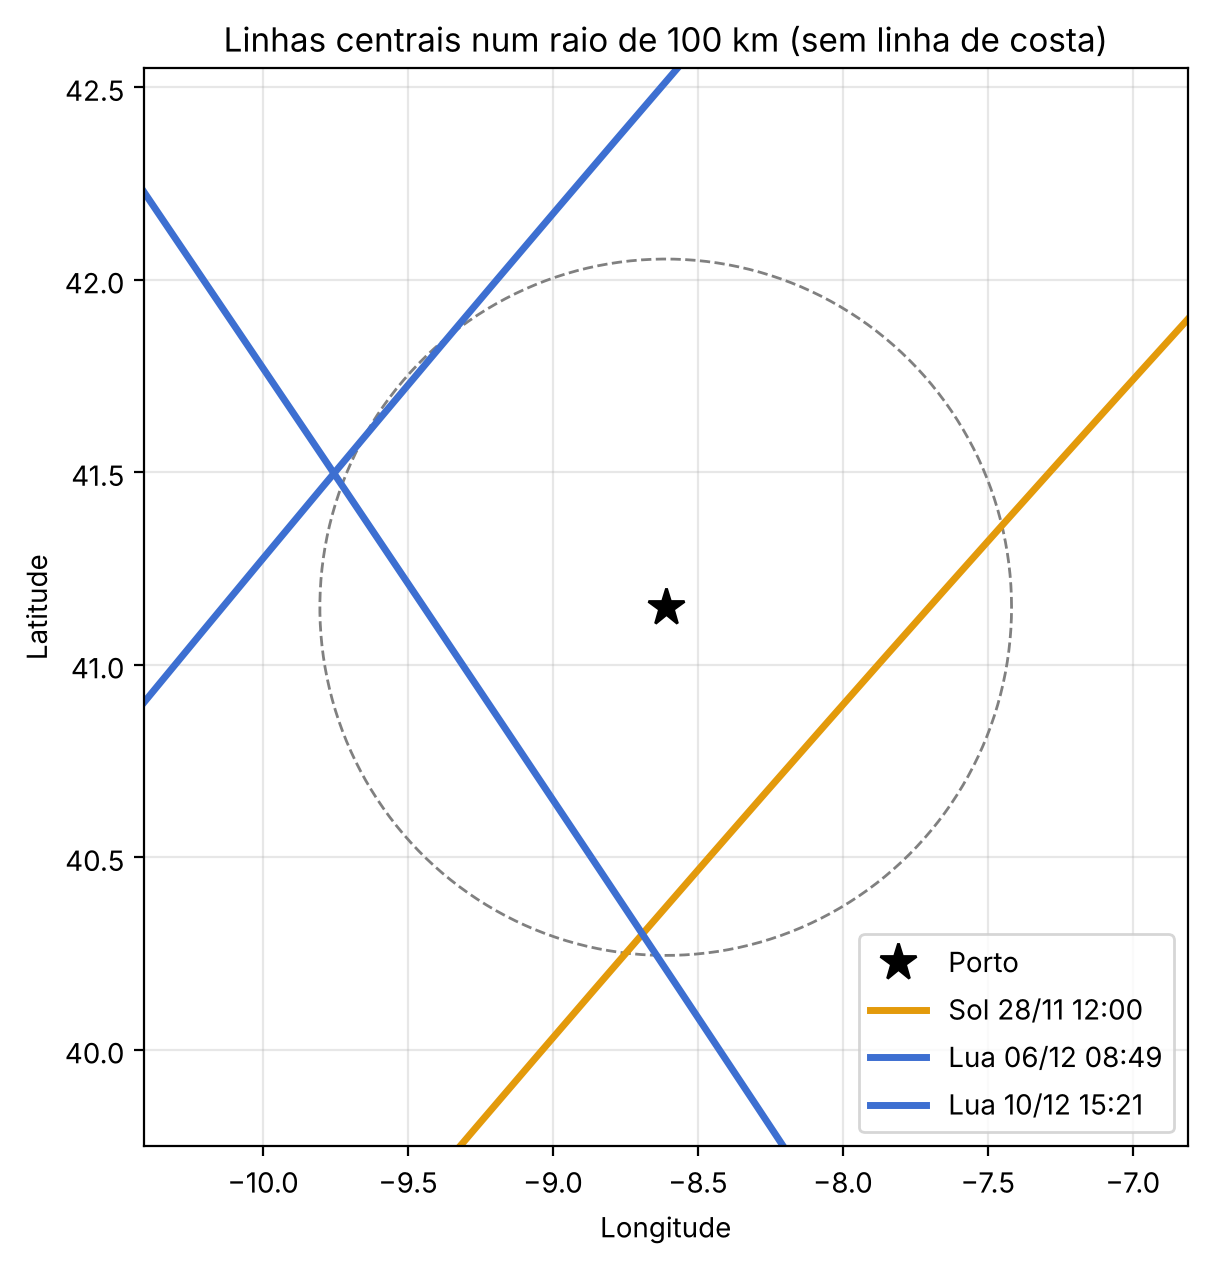

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
th = np.linspace(0, 2*np.pi, 200)
ax.plot(LON + RAIO_KM/(111.32*np.cos(np.radians(LAT)))*np.cos(th), LAT + RAIO_KM/110.57*np.sin(th), '--', color='grey', lw=1)
ax.plot(LON, LAT, 'k*', ms=14, label=NOME)
for c, r in zip(centros, res):
    segs = np.arange(-40, 40, 0.05)
    t = ts.tt_jd(c['t_central'].tt + segs/86400)
    corpo = sun if c['corpo'] == 'Sol' else moon
    la, lo = ponto_no_chao(iss.at(t).frame_xyz(itrs).km, earth.at(t).observe(corpo).apparent().frame_xyz(itrs).km)
    cor = '#E39A0B' if c['corpo'] == 'Sol' else '#3D6FD1'
    ax.plot(lo, la, color=cor, lw=2.5, label=f"{c['corpo']} {c['t_central'].utc_strftime('%d/%m %H:%M')}")
ax.set_xlim(LON-1.8, LON+1.8); ax.set_ylim(LAT-1.4, LAT+1.4)
ax.set_aspect(1/np.cos(np.radians(LAT))); ax.grid(alpha=.3)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(loc='lower right')
ax.set_title(f'Linhas centrais num raio de {RAIO_KM} km (sem linha de costa)'); plt.show()

## Simulação no disco (observador em cima da linha central)

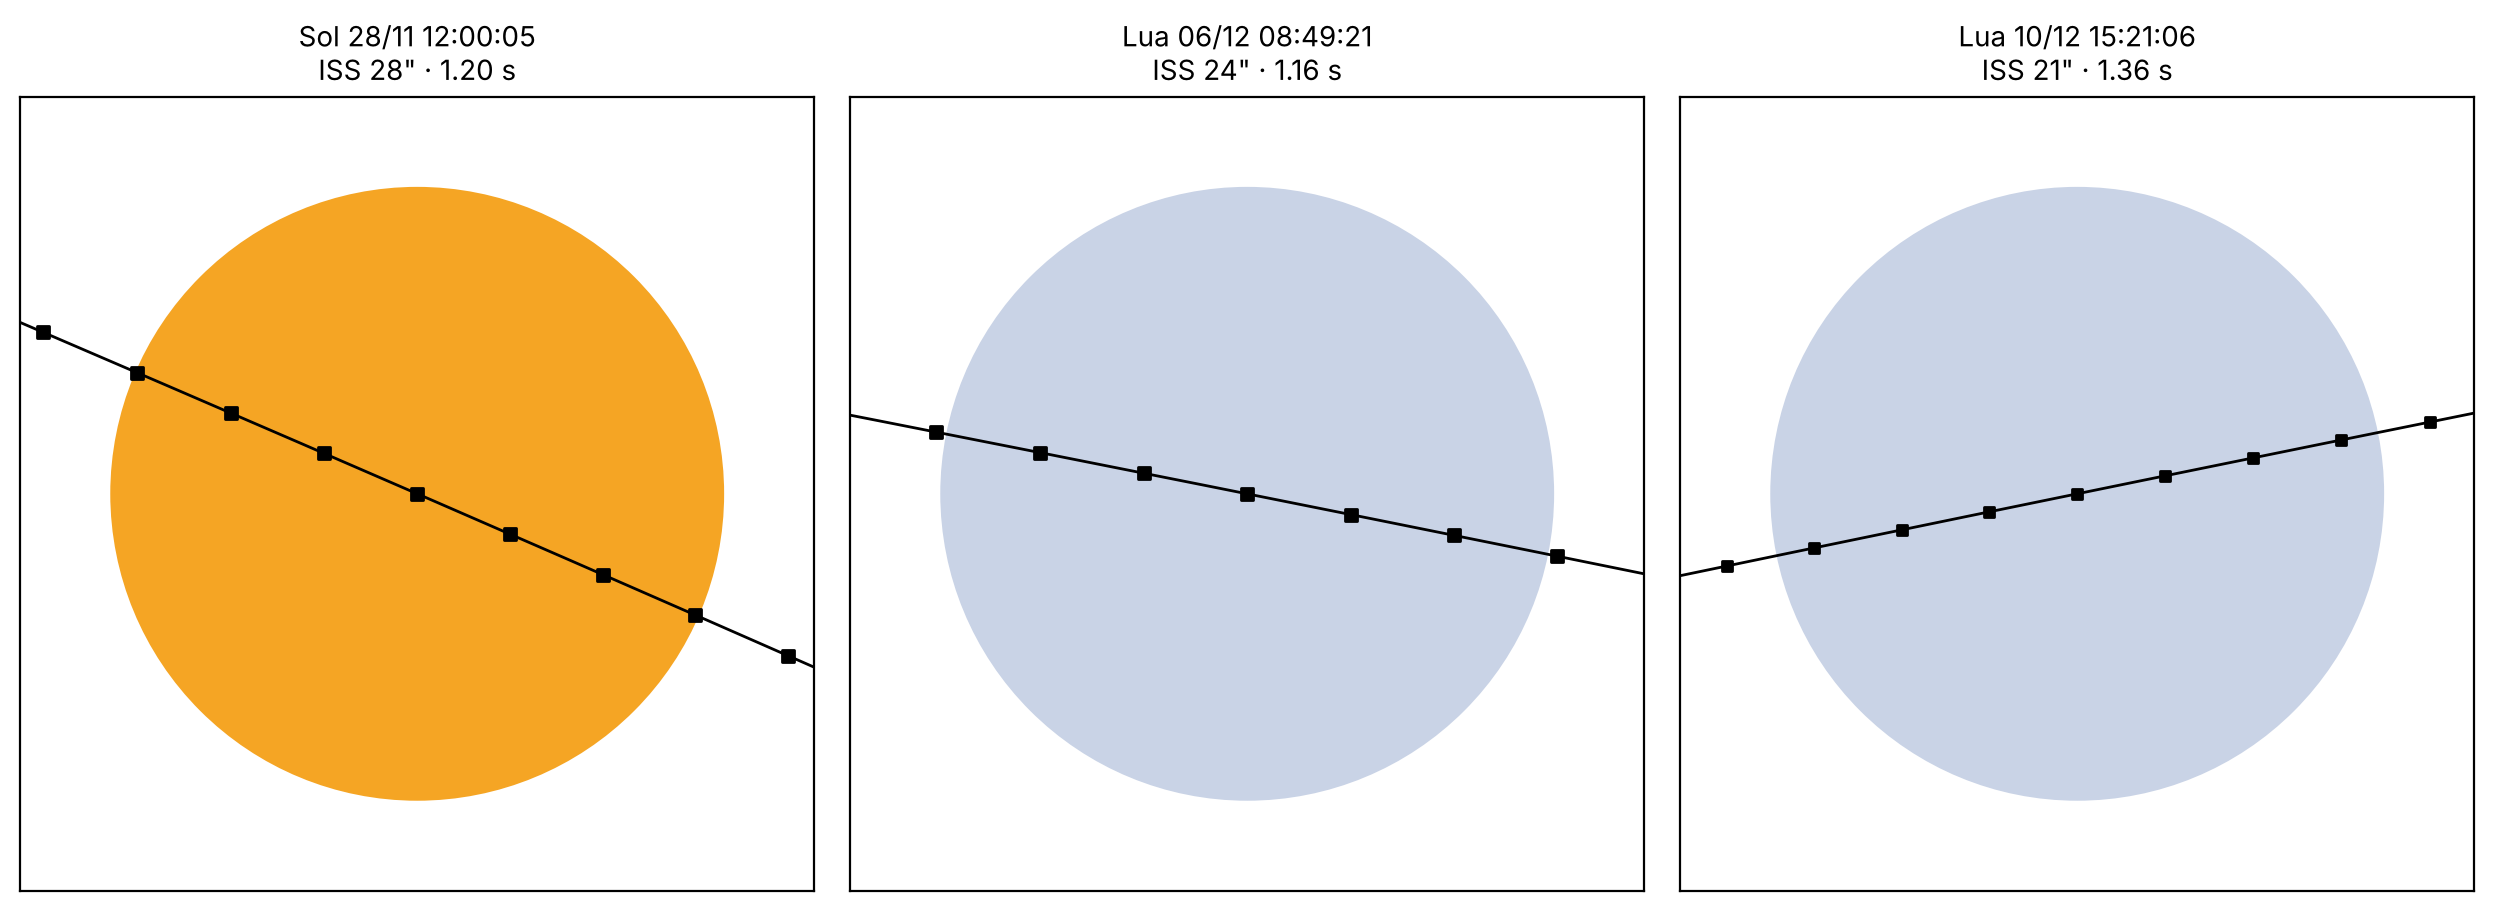

In [6]:
fig, axs = plt.subplots(1, len(centros), figsize=(4.2*len(centros), 4.4))
axs = np.atleast_1d(axs)
for ax, c in zip(axs, centros):
    corpo = sun if c['corpo'] == 'Sol' else moon
    topo = wgs84.latlon(c['lat_linha'] if 'lat_linha' in c else LAT, c['lon_linha'])
    segs = np.arange(-1.2, 1.2, 0.01)
    t = ts.tt_jd(c['t_central'].tt + segs/86400)
    a_i, z_i, _ = (iss - topo).at(t).altaz()
    a_c, z_c, _ = (earth + topo).at(t).observe(corpo).apparent().altaz()
    dx = (z_i.degrees - z_c.degrees) * np.cos(a_c.radians) * 3600
    dy = (a_i.degrees - a_c.degrees) * 3600
    R = c['raio_corpo_arcsec']
    ax.add_patch(plt.Circle((0, 0), R, color='#F5A524' if c['corpo']=='Sol' else '#C9D3E6'))
    ax.plot(dx, dy, color='k', lw=1)
    k = np.abs(segs*100 % 20) < 1e-6
    ax.scatter(dx[k], dy[k], s=(c['tam_iss_arcsec']/R*150)**2, marker='s', color='k')
    ax.set_xlim(-1.3*R, 1.3*R); ax.set_ylim(-1.3*R, 1.3*R); ax.set_aspect(1)
    ax.set_title(f"{c['corpo']} {c['t_central'].utc_strftime('%d/%m %H:%M:%S')}\nISS {c['tam_iss_arcsec']:.0f}\" · {c['duracao_s']:.2f} s", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Próximo passo: comparação externa

Abre o **transit-finder.com**, escolhe **Porto**, raio **100 km**, e confirma se aparecem estes trânsitos com hora (±1–2 s) e linha central (±~0,5 km) semelhantes.

Notas:
- O TLE usado é de 25/11. O transit-finder usa um mais recente; para trânsitos a 10–14 dias, diferenças de alguns segundos/km são normais (arrasto, possíveis reboosts).
- Não consegui aceder ao transit-finder.com a partir deste ambiente, por isso a comparação tem de ser feita por ti.